# **H3_Character_Sheet_Generator**
- Github repo: https://github.com/MiniMax-AI/MiniMax-H3-Image

- P-Image repo: https://huggingface.co/PrunaAI/P-Image-OSS

- Notebook source: https://github.com/Isi-dev/Google-Colab_Notebooks

In [17]:
# @title 💥 1. Prepare Environment & Download Models {"single-column":true}
import os
import sys
import shutil
import subprocess
import re
import time
import gc
from pathlib import Path
from IPython.display import clear_output, display, HTML, Image as IPImage

os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

# 1. Directory alignment & Repositories Setup
%cd /content
if not os.path.exists("ComfyUI"):
    !git clone https://github.com/comfyanonymous/ComfyUI.git

%cd /content/ComfyUI/custom_nodes
if not os.path.exists("ComfyUI_GGUF"):
    !git clone --branch leejet_27_09_2026 https://github.com/Isi-dev/ComfyUI_GGUF.git

if not os.path.exists("ComfyUI_ReActor"):
    !git clone https://github.com/Isi-dev/ComfyUI_ReActor

# Ensure ComfyUI_GGUF loader recognizes the "minimax_h3" architecture
gguf_loader_path = "/content/ComfyUI/custom_nodes/ComfyUI_GGUF/loader.py"
if os.path.exists(gguf_loader_path):
    with open(gguf_loader_path, "r") as f:
        loader_code = f.read()
    if '"minimax_h3"' not in loader_code and "'minimax_h3'" not in loader_code:
        loader_code = loader_code.replace('"qwen_image"', '"qwen_image", "minimax_h3"')
        with open(gguf_loader_path, "w") as f:
            f.write(loader_code)

%cd /content/ComfyUI
!pip install -r requirements.txt
!pip install gguf huggingface_hub hf_transfer insightface==0.7.3 sageattention triton imageio imageio-ffmpeg opencv-python onnx opencv-python segment_anything ultralytics onnxruntime
!pip install onnxruntime-gpu -y
!apt -y install -qq aria2 ffmpeg

clear_output()
print("✅ Repositories & core requirements installed.")

# @markdown ---
# @markdown ### **Authentication & Model Suite Selection**
hf_token = "" # @param {type:"string"}
civitai_token = "" # @param {type:"string"}
model_download_selection = "Download Both MiniMax-H3-Image & P-H3-Image" # @param ["Download MiniMax-H3-Image Only", "Download P-H3-Image Only", "Download Both MiniMax-H3-Image & P-H3-Image"]

# @markdown ---
# @markdown ### **A. MiniMax-H3-Image Models (For `MiniMax H3 Image Conditioning`)**
# @markdown *If a custom URL is pasted into any `custom_minimax_*_url` field below, it automatically overrides the corresponding preset.*
minimax_diffusion_preset = "Unsloth GGUF Q4_K_M (Low VRAM GGUF)" # @param ["Comfy-Org INT8 ConvRot (21 GB - Balanced)", "Comfy-Org W4A8 (12.5 GB - Low VRAM)", "Comfy-Org BF16 (Highest Quality)", "Unsloth GGUF Q4_K_M (Low VRAM GGUF)"]
custom_minimax_diffusion_url = "" # @param {type:"string"}

minimax_text_encoder_preset = "Comfy-Org Qwen3-VL 32B NVFP4 AWQ (15.7 GB)" # @param ["Comfy-Org Qwen3-VL 32B NVFP4 AWQ (15.7 GB)", "Comfy-Org Qwen3-VL 32B INT8 ConvRot"]
custom_minimax_text_encoder_url = "" # @param {type:"string"}

minimax_vae_url = "https://huggingface.co/Comfy-Org/MiniMax-H3-Image/resolve/main/vae/minimax_h3_image_vae_fp16.safetensors" # @param {type:"string"}

# @markdown ---
# @markdown ### **B. P-H3-Image Models (For `P-H3 Image Conditioning`)**
# @markdown *If a custom URL is pasted into any `custom_ph3_*_url` field below, it automatically overrides the corresponding preset.*
ph3_diffusion_preset = "PrunaAI P-H3 W4A8 (Low VRAM)" # @param ["PrunaAI P-H3 INT8 ConvRot (21.2 GB - Balanced)", "PrunaAI P-H3 W4A8 (Low VRAM)", "PrunaAI P-H3 BF16 (40.5 GB - Highest Quality)", "AtomicChat P-H3 GGUF AD-Q4_K (Low VRAM GGUF)"]
custom_ph3_diffusion_url = "" # @param {type:"string"}

ph3_text_encoder_preset = "PrunaAI Qwen3-VL 4B W4A8 (Low VRAM)" # @param ["PrunaAI Qwen3-VL 4B INT8 ConvRot", "PrunaAI Qwen3-VL 4B W4A8 (Low VRAM)", "PrunaAI Qwen3-VL 4B BF16 (9.1 GB)"]
custom_ph3_text_encoder_url = "" # @param {type:"string"}

ph3_vae_preset = "PrunaAI P-H3 VAE BF16 (5.56 GB)" # @param ["PrunaAI P-H3 VAE BF16 (5.56 GB)", "PrunaAI P-H3 VAE INT8 (Low VRAM)"]
custom_ph3_vae_url = "" # @param {type:"string"}

# @markdown ---
# @markdown ### **C. Optional Custom LoRAs (HuggingFace or Civitai URLs)**
download_lora_1 = False # @param {type:"boolean"}
lora_1_url = "" # @param {type:"string"}

download_lora_2 = False # @param {type:"boolean"}
lora_2_url = "" # @param {type:"string"}

download_lora_3 = False # @param {type:"boolean"}
lora_3_url = "" # @param {type:"string"}

download_lora_4 = False # @param {type:"boolean"}
lora_4_url = "" # @param {type:"string"}

download_lora_5 = False # @param {type:"boolean"}
lora_5_url = "" # @param {type:"string"}

# ------------------------------------------------------------------------------
# Resolve MiniMax-H3-Image URLs (Custom URL overrides preset whenever provided)
# ------------------------------------------------------------------------------
if custom_minimax_diffusion_url.strip():
    resolved_minimax_diff_url = custom_minimax_diffusion_url.strip()
elif "W4A8" in minimax_diffusion_preset:
    resolved_minimax_diff_url = "https://huggingface.co/Comfy-Org/MiniMax-H3-Image/resolve/main/diffusion_models/minimax_h3_image_pruned_w4a8.safetensors"
elif "BF16" in minimax_diffusion_preset:
    resolved_minimax_diff_url = "https://huggingface.co/Comfy-Org/MiniMax-H3-Image/resolve/main/diffusion_models/minimax_h3_image_pruned_bf16.safetensors"
elif "GGUF" in minimax_diffusion_preset:
    resolved_minimax_diff_url = "https://huggingface.co/unsloth/MiniMax-H3-Image-GGUF/resolve/main/minimax_h3_image_pruned-Q4_K_M.gguf"
else:
    resolved_minimax_diff_url = "https://huggingface.co/Comfy-Org/MiniMax-H3-Image/resolve/main/diffusion_models/minimax_h3_image_pruned_int8_convrot.safetensors"

if custom_minimax_text_encoder_url.strip():
    resolved_minimax_clip_url = custom_minimax_text_encoder_url.strip()
elif "INT8" in minimax_text_encoder_preset:
    resolved_minimax_clip_url = "https://huggingface.co/Comfy-Org/MiniMax-H3-Image/resolve/main/text_encoders/qwen3vl_32b_minimax_h3_int8_convrot.safetensors"
else:
    resolved_minimax_clip_url = "https://huggingface.co/Comfy-Org/MiniMax-H3-Image/resolve/main/text_encoders/qwen3vl_32b_minimax_h3_nvfp4_awq.safetensors"

resolved_minimax_vae_url = minimax_vae_url.strip()

# ------------------------------------------------------------------------------
# Resolve P-H3-Image URLs (Custom URL overrides preset whenever provided)
# ------------------------------------------------------------------------------
if custom_ph3_diffusion_url.strip():
    resolved_ph3_diff_url = custom_ph3_diffusion_url.strip()
elif "W4A8" in ph3_diffusion_preset:
    resolved_ph3_diff_url = "https://huggingface.co/PrunaAI/P-H3-Image-Comfy/resolve/main/diffusion_models/p-h3-image_w4a8.safetensors"
elif "BF16" in ph3_diffusion_preset:
    resolved_ph3_diff_url = "https://huggingface.co/PrunaAI/P-H3-Image-Comfy/resolve/main/diffusion_models/p-h3-image_bf16.safetensors"
elif "GGUF" in ph3_diffusion_preset:
    resolved_ph3_diff_url = "https://huggingface.co/AtomicChat/P-H3-Image-GGUF/resolve/main/p-h3-image-AD-Q4_K.gguf"
else:
    resolved_ph3_diff_url = "https://huggingface.co/PrunaAI/P-H3-Image-Comfy/resolve/main/diffusion_models/p-h3-image_int8_convrot.safetensors"

if custom_ph3_text_encoder_url.strip():
    resolved_ph3_clip_url = custom_ph3_text_encoder_url.strip()
elif "W4A8" in ph3_text_encoder_preset:
    resolved_ph3_clip_url = "https://huggingface.co/PrunaAI/P-H3-Image-Comfy/resolve/main/text_encoders/p-h3-image_text_encoder_w4a8.safetensors"
elif "BF16" in ph3_text_encoder_preset:
    resolved_ph3_clip_url = "https://huggingface.co/PrunaAI/P-H3-Image-Comfy/resolve/main/text_encoders/p-h3-image_text_encoder_bf16.safetensors"
else:
    resolved_ph3_clip_url = "https://huggingface.co/PrunaAI/P-H3-Image-Comfy/resolve/main/text_encoders/p-h3-image_text_encoder_int8_convrot.safetensors"

if custom_ph3_vae_url.strip():
    resolved_ph3_vae_url = custom_ph3_vae_url.strip()
elif "INT8" in ph3_vae_preset:
    resolved_ph3_vae_url = "https://huggingface.co/PrunaAI/P-H3-Image-Comfy/resolve/main/vae/p-h3-image_vae_int8.safetensors"
else:
    resolved_ph3_vae_url = "https://huggingface.co/PrunaAI/P-H3-Image-Comfy/resolve/main/vae/p-h3-image_vae_bf16.safetensors"

# ------------------------------------------------------------------------------
# Download Helpers
# ------------------------------------------------------------------------------
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "1"
from huggingface_hub import hf_hub_download

def download_hf_file(repo_id, repo_relative_path, local_destination, token=None):
    if not repo_relative_path or repo_relative_path == "None":
        return None
    os.makedirs(local_destination, exist_ok=True)
    filename = os.path.basename(repo_relative_path)
    destination = os.path.join(local_destination, filename)
    if os.path.isfile(destination):
        print(f"⏭️ Already exists: {destination}")
        return filename
    print(f"⬇️ Downloading HF File: {repo_id}/{repo_relative_path}")
    try:
        downloaded_path = hf_hub_download(
            repo_id=repo_id,
            filename=repo_relative_path,
            token=token if token else None
        )
        shutil.copy2(downloaded_path, destination)
        try:
            os.remove(downloaded_path)
        except Exception:
            pass
        print(f"✅ Downloaded: {destination}")
        return filename
    except Exception as e:
        print(f"❌ Download failed for {repo_relative_path}: {e}")
        return None

def download_civitai_model(civitai_link, token, folder="models/loras"):
    os.makedirs(folder, exist_ok=True)
    try:
        model_id = civitai_link.split("/models/")[1].split("?")[0]
    except IndexError:
        raise ValueError("Invalid Civitai URL format. Expected: https://civitai.com/api/download/models/<ID>")
    civitai_url = f"https://civitai.com/api/download/models/{model_id}?type=Model&format=SafeTensor"
    if token:
        civitai_url += f"&token={token}"
    timestamp = time.strftime("%Y%m%d_%H%M%S")
    filename = f"civitai_model_{timestamp}.safetensors"
    full_path = os.path.join(folder, filename)
    print(f"⬇️ Downloading Civitai model to {full_path}...")
    cmd = f'wget --max-redirect=10 --show-progress "{civitai_url}" -O "{full_path}"'
    os.system(cmd)
    if os.path.exists(full_path) and os.path.getsize(full_path) > 0:
        print(f"✅ Civitai Download Complete: {filename}")
        return filename
    else:
        print("❌ Civitai Download failed.")
        return None

def download_generic_url(url, dest_dir, token_hf="", token_civitai=""):
    if not url or not url.strip():
        return None
    url = url.strip()
    if "civitai.com" in url.lower():
        return download_civitai_model(url, token_civitai, dest_dir)
    hf_match = re.search(r'huggingface\.co/([^/]+/[^/]+)/(?:resolve|blob)/[^/]+/(.+)', url)
    if hf_match:
        repo_id = hf_match.group(1)
        rel_path = hf_match.group(2)
        return download_hf_file(repo_id, rel_path, dest_dir, token_hf)
    filename = url.split('/')[-1].split('?')[0]
    os.makedirs(dest_dir, exist_ok=True)
    cmd = ['aria2c', '--console-log-level=error', '-c', '-x', '16', '-s', '16', '-k', '1M', '-d', dest_dir, '-o', filename, url]
    subprocess.run(cmd, check=False)
    return filename

token_str = hf_token.strip()
civ_token_str = civitai_token.strip()

# Initialize Model File Variables for Both Suites
minimax_unet_file = None
minimax_clip_file = None
minimax_vae_file = None

ph3_unet_file = None
ph3_clip_file = None
ph3_vae_file = None

do_minimax = model_download_selection in ["Download MiniMax-H3-Image Only", "Download Both MiniMax-H3-Image & P-H3-Image"]
do_ph3 = model_download_selection in ["Download P-H3-Image Only", "Download Both MiniMax-H3-Image & P-H3-Image"]

if do_minimax:
    print("\n--- ⬇️ Downloading MiniMax-H3-Image Models ---")
    minimax_unet_file = download_generic_url(resolved_minimax_diff_url, "models/diffusion_models", token_str, civ_token_str)
    minimax_clip_file = download_generic_url(resolved_minimax_clip_url, "models/text_encoders", token_str, civ_token_str)
    minimax_vae_file = download_generic_url(resolved_minimax_vae_url, "models/vae", token_str, civ_token_str)

if do_ph3:
    print("\n--- ⬇️ Downloading P-H3-Image Models ---")
    ph3_unet_file = download_generic_url(resolved_ph3_diff_url, "models/diffusion_models", token_str, civ_token_str)
    ph3_clip_file = download_generic_url(resolved_ph3_clip_url, "models/text_encoders", token_str, civ_token_str)
    ph3_vae_file = download_generic_url(resolved_ph3_vae_url, "models/vae", token_str, civ_token_str)

lora_files = []
lora_configs = [
    (download_lora_1, lora_1_url),
    (download_lora_2, lora_2_url),
    (download_lora_3, lora_3_url),
    (download_lora_4, lora_4_url),
    (download_lora_5, lora_5_url),
]

retry_face_model_download = False # @param {type:"boolean"}

face_folder_path = "/content/ComfyUI/models/insightface/models"
if (not os.path.exists(face_folder_path)) or retry_face_model_download:
    if not os.path.exists(face_folder_path):
        print(f"Folder '{face_folder_path}' does not exist. Creating it now...")
        !mkdir -p /content/ComfyUI/models/insightface/models
    !aria2c --console-log-level=error -c -x 16 -s 16 -k 1M https://huggingface.co/Isi99999/ruffs/resolve/main/buffalo_l.zip -d /content/ComfyUI/models/insightface/models -o buffalo_l.zip
    !unzip -q /content/ComfyUI/models/insightface/models/buffalo_l.zip -d /content/ComfyUI/models/insightface/models/
    !rm /content/ComfyUI/models/insightface/models/buffalo_l.zip

    !mkdir -p /content/ComfyUI/models/insightface
    !aria2c --console-log-level=error -c -x 16 -s 16 -k 1M https://huggingface.co/Isi99999/ruffs/resolve/main/RUfFSp/models/inswapper_128.onnx -d /content/ComfyUI/models/insightface -o inswapper_128.onnx

    !mkdir -p /content/ComfyUI/models/facedetection
    !aria2c --console-log-level=error -c -x 16 -s 16 -k 1M https://huggingface.co/Isi99999/ruffs/resolve/main/detection_Resnet50_Final.pth -d /content/ComfyUI/models/facedetection -o detection_Resnet50_Final.pth
    !aria2c --console-log-level=error -c -x 16 -s 16 -k 1M https://huggingface.co/Isi99999/ruffs/resolve/main/parsing_parsenet.pth -d /content/ComfyUI/models/facedetection -o parsing_parsenet.pth

    !mkdir -p /content/ComfyUI/models/facerestore_models
    !aria2c --console-log-level=error -c -x 16 -s 16 -k 1M https://huggingface.co/Isi99999/ruffs/resolve/main/GFPGANv1.4.pth -d /content/ComfyUI/models/facerestore_models -o GFPGANv1.4.pth





print("\n--- ⬇️ Checking Optional Custom LoRAs ---")
for idx, (enabled, url) in enumerate(lora_configs, 1):
    if enabled and url.strip():
        fname = download_generic_url(url, "models/loras", token_str, civ_token_str)
        lora_files.append(fname)
        if fname:
            print(f"LoRA {idx} registered: {fname}")
    else:
        lora_files.append(None)

# Initialize ComfyUI Classes & Execution Imports
import torch
import numpy as np
from PIL import Image

sys.path.insert(0, '/content/ComfyUI')
from comfy import model_management
from nodes import (
    UNETLoader,
    CLIPLoader,
    VAELoader,
    VAEDecode,
    LoadImage,
    LoraLoaderModelOnly,
    ConditioningZeroOut,
    KSampler,
    SaveImage
)
from comfy_extras.nodes_minimax_h3 import (
    MiniMaxH3ImageConditioning,
    PH3ImageConditioning,
    MiniMaxH3SigmaShift
)

from custom_nodes.ComfyUI_ReActor.nodes import reactor

clear_output()
print("==================================================================")
print("✅ Environment & Model Setup Complete!")
print("==================================================================")
if do_minimax:
    print(f"📦 MiniMax-H3 Suite : UNET={minimax_unet_file} | CLIP={minimax_clip_file} | VAE={minimax_vae_file}")
if do_ph3:
    print(f"📦 P-H3-Image Suite : UNET={ph3_unet_file} | CLIP={ph3_clip_file} | VAE={ph3_vae_file}")
print("==================================================================\nRun the next cell.")

✅ Environment & Model Setup Complete!
📦 MiniMax-H3 Suite : UNET=minimax_h3_image_pruned-Q4_K_M.gguf | CLIP=qwen3vl_32b_minimax_h3_nvfp4_awq.safetensors | VAE=minimax_h3_image_vae_fp16.safetensors
📦 P-H3-Image Suite : UNET=p-h3-image_w4a8.safetensors | CLIP=p-h3-image_text_encoder_w4a8.safetensors | VAE=p-h3-image_vae_bf16.safetensors
Run the next cell.


Upload reference images to /content/ComfyUI/input
(You can select multiple images at once, or cancel if already uploaded):



--- 🖼️ Image Bank Inventory (2 images) ---


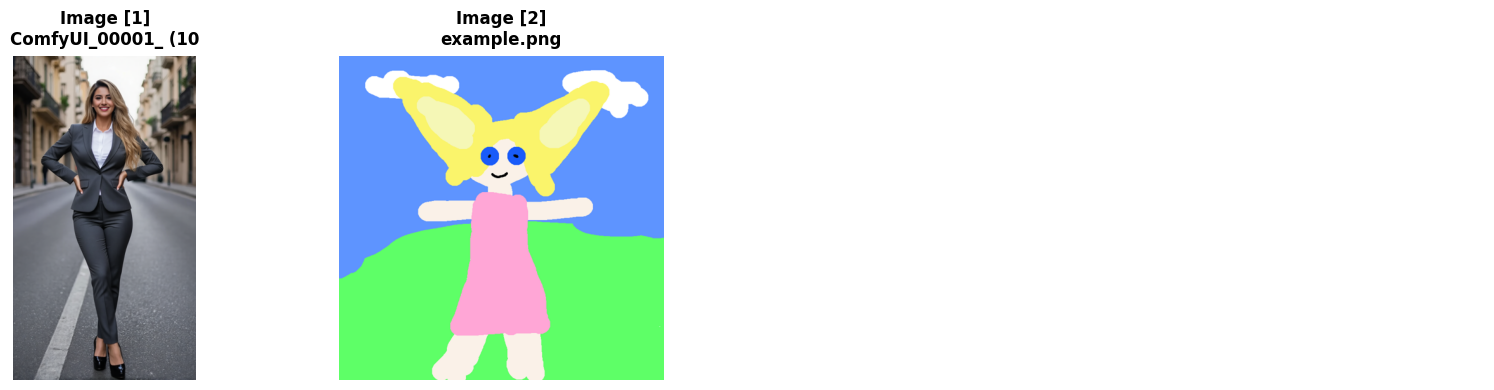

In [14]:
# @title 📥 2. Upload & View Media Bank {"single-column":true}
import os
import math
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

BANK_DIR = '/content/ComfyUI/input'
os.makedirs(BANK_DIR, exist_ok=True)
os.chdir(BANK_DIR)

print(f"Upload reference images to {BANK_DIR}\n(You can select multiple images at once, or cancel if already uploaded):")
uploaded = files.upload()

os.chdir('/content/ComfyUI')

all_files = os.listdir(BANK_DIR)
available_images = sorted([f for f in all_files if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))])

if available_images:
    print(f"\n--- 🖼️ Image Bank Inventory ({len(available_images)} images) ---")
    cols = 4
    rows = math.ceil(len(available_images) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))

    if rows == 1 and cols == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for i, img_name in enumerate(available_images):
        img_path = os.path.join(BANK_DIR, img_name)
        img = Image.open(img_path)
        img.thumbnail((512, 512))

        ax = axes[i]
        ax.imshow(img)
        ax.set_title(f"Image [{i+1}]\n{img_name[:18]}", fontsize=12, fontweight='bold', pad=8)
        ax.axis('off')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("\nNo images in the bank yet.")

💥 H3 CHARACTER SHEET — 10 ACTIVE VIEWS
🔹 Conditioning Node : P-H3 Image Conditioning
🔹 Target Resolution : 4320 x 1856 (8.02 MP)
🔹 Seed=3403116873624684743
------------------------------------------------------------------
📝 Compiled Prompt:
Edit <Picture 1>. Create a 10-view multi-angle turnaround reference sheet of the exact subject shown in <Picture 1> on a pure solid white studio background. <Picture 1> is the primary character reference (Primary Character Identity & Full Appearance); preserve the exact person/character, facial identity, skin tone, hair design, body proportions, color palette, and medium from <Picture 1>. Use <Picture 2> strictly as an invisible spatial placement guide for the position and scale of each head and full-body view of the subject from <Picture 1>. Render all views on one continuous, seamless, borderless pure solid white studio background with NO grid lines, NO rectangular boxes, NO panel frames, and NO dividing lines. LEFT SECTION (2 stacked/grid head-a

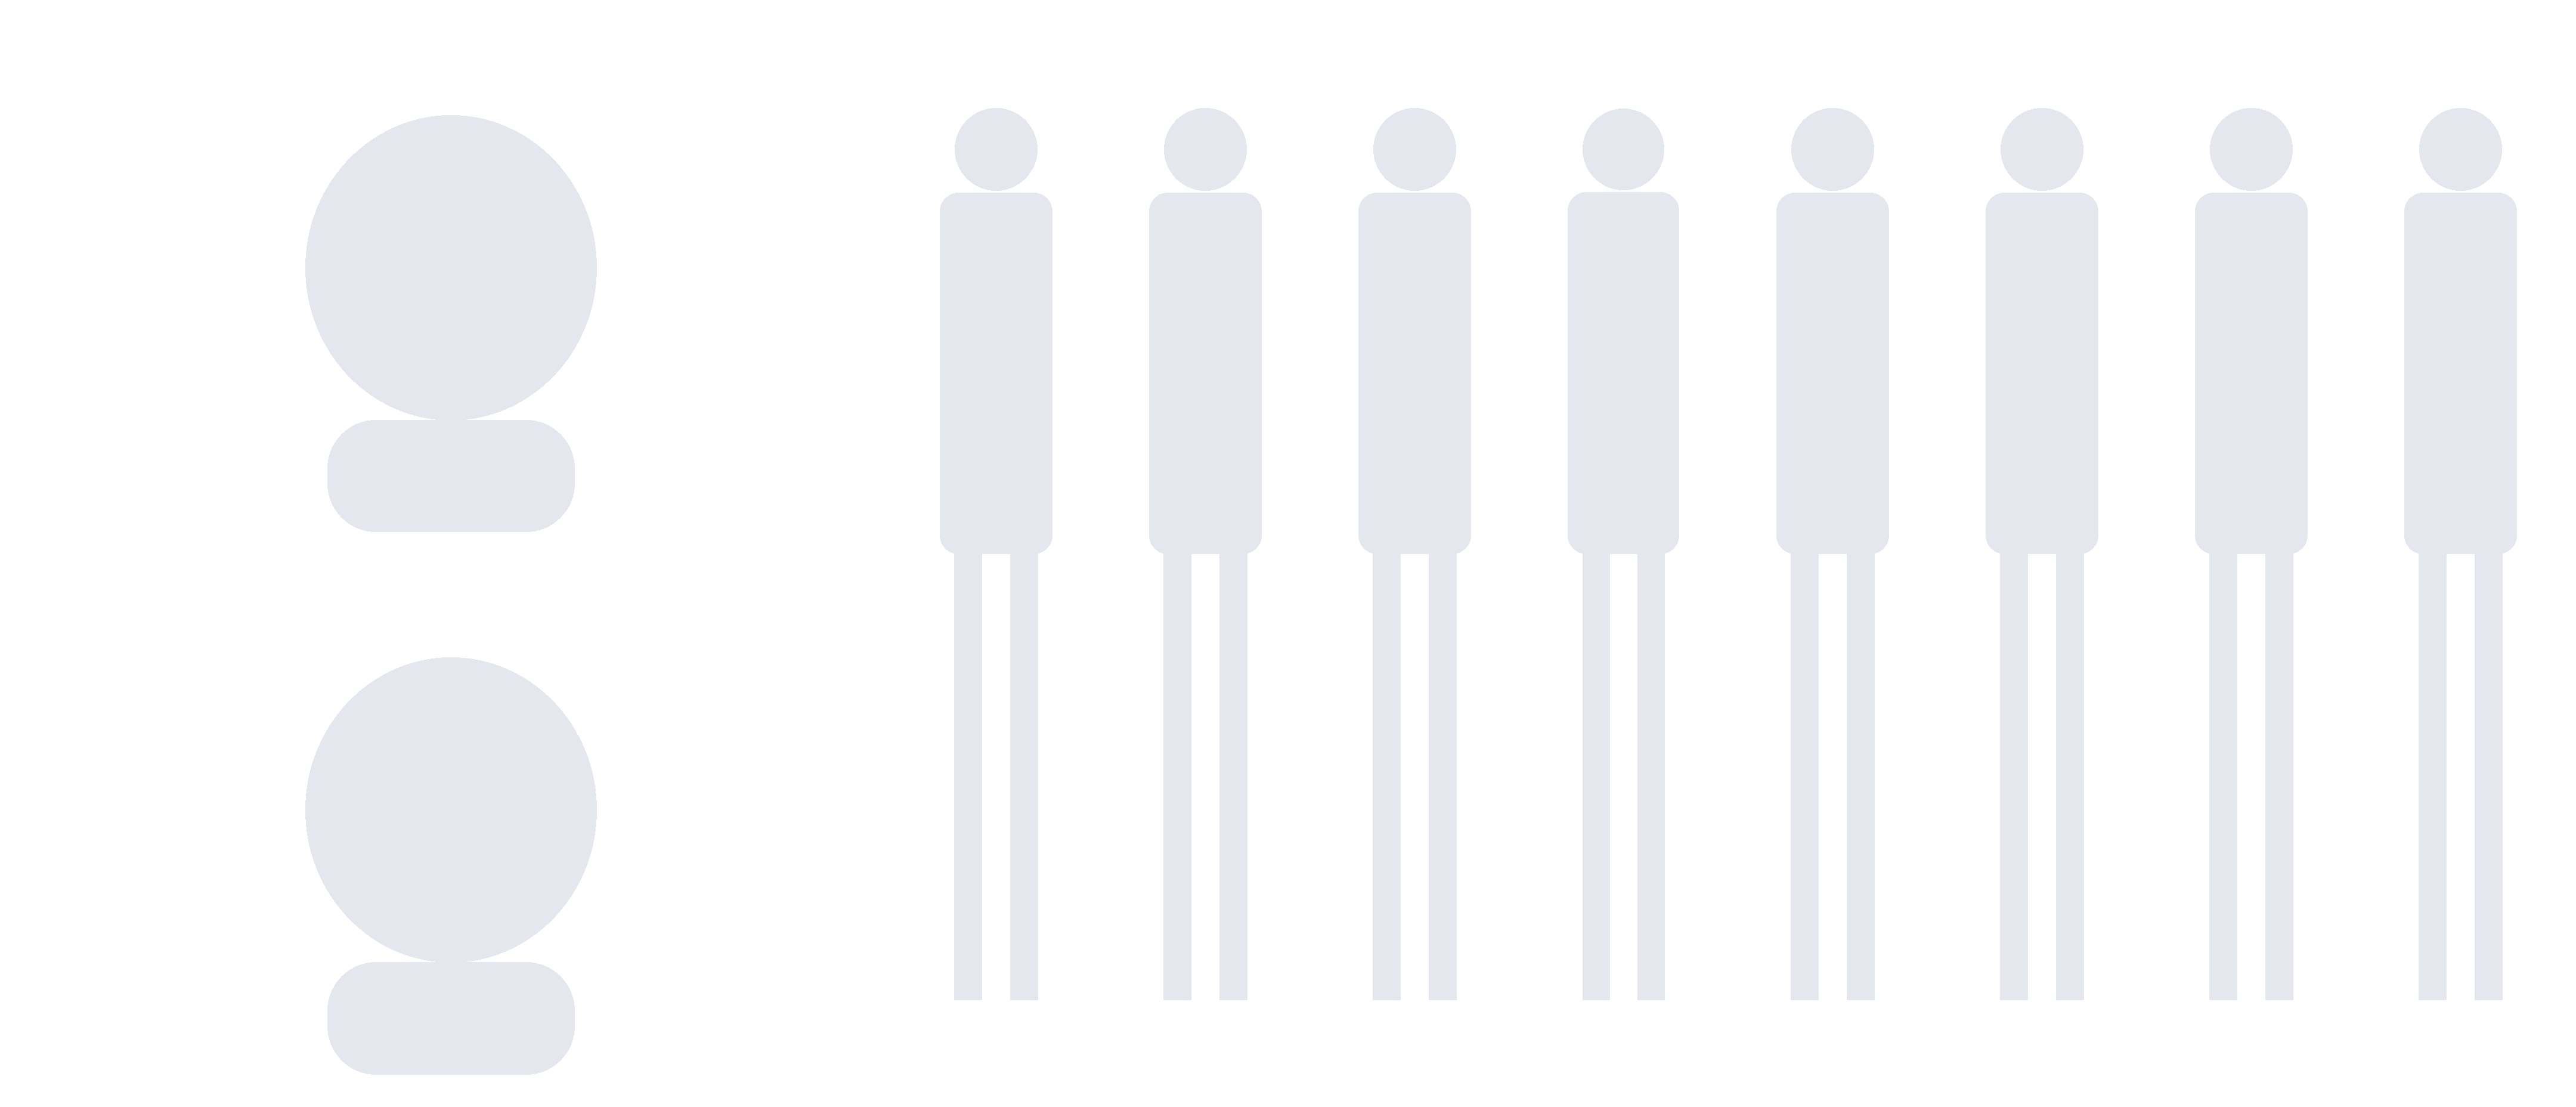

⏳ Encoding references and prompt with P-H3 Image Conditioning...
Generating Character Sheet...


  0%|          | 0/8 [00:00<?, ?it/s]

✅ Character Sheet Saved to: /content/ComfyUI/output/PH3_Character_Sheet_10views_20261119_170654.png

Restoring faces...


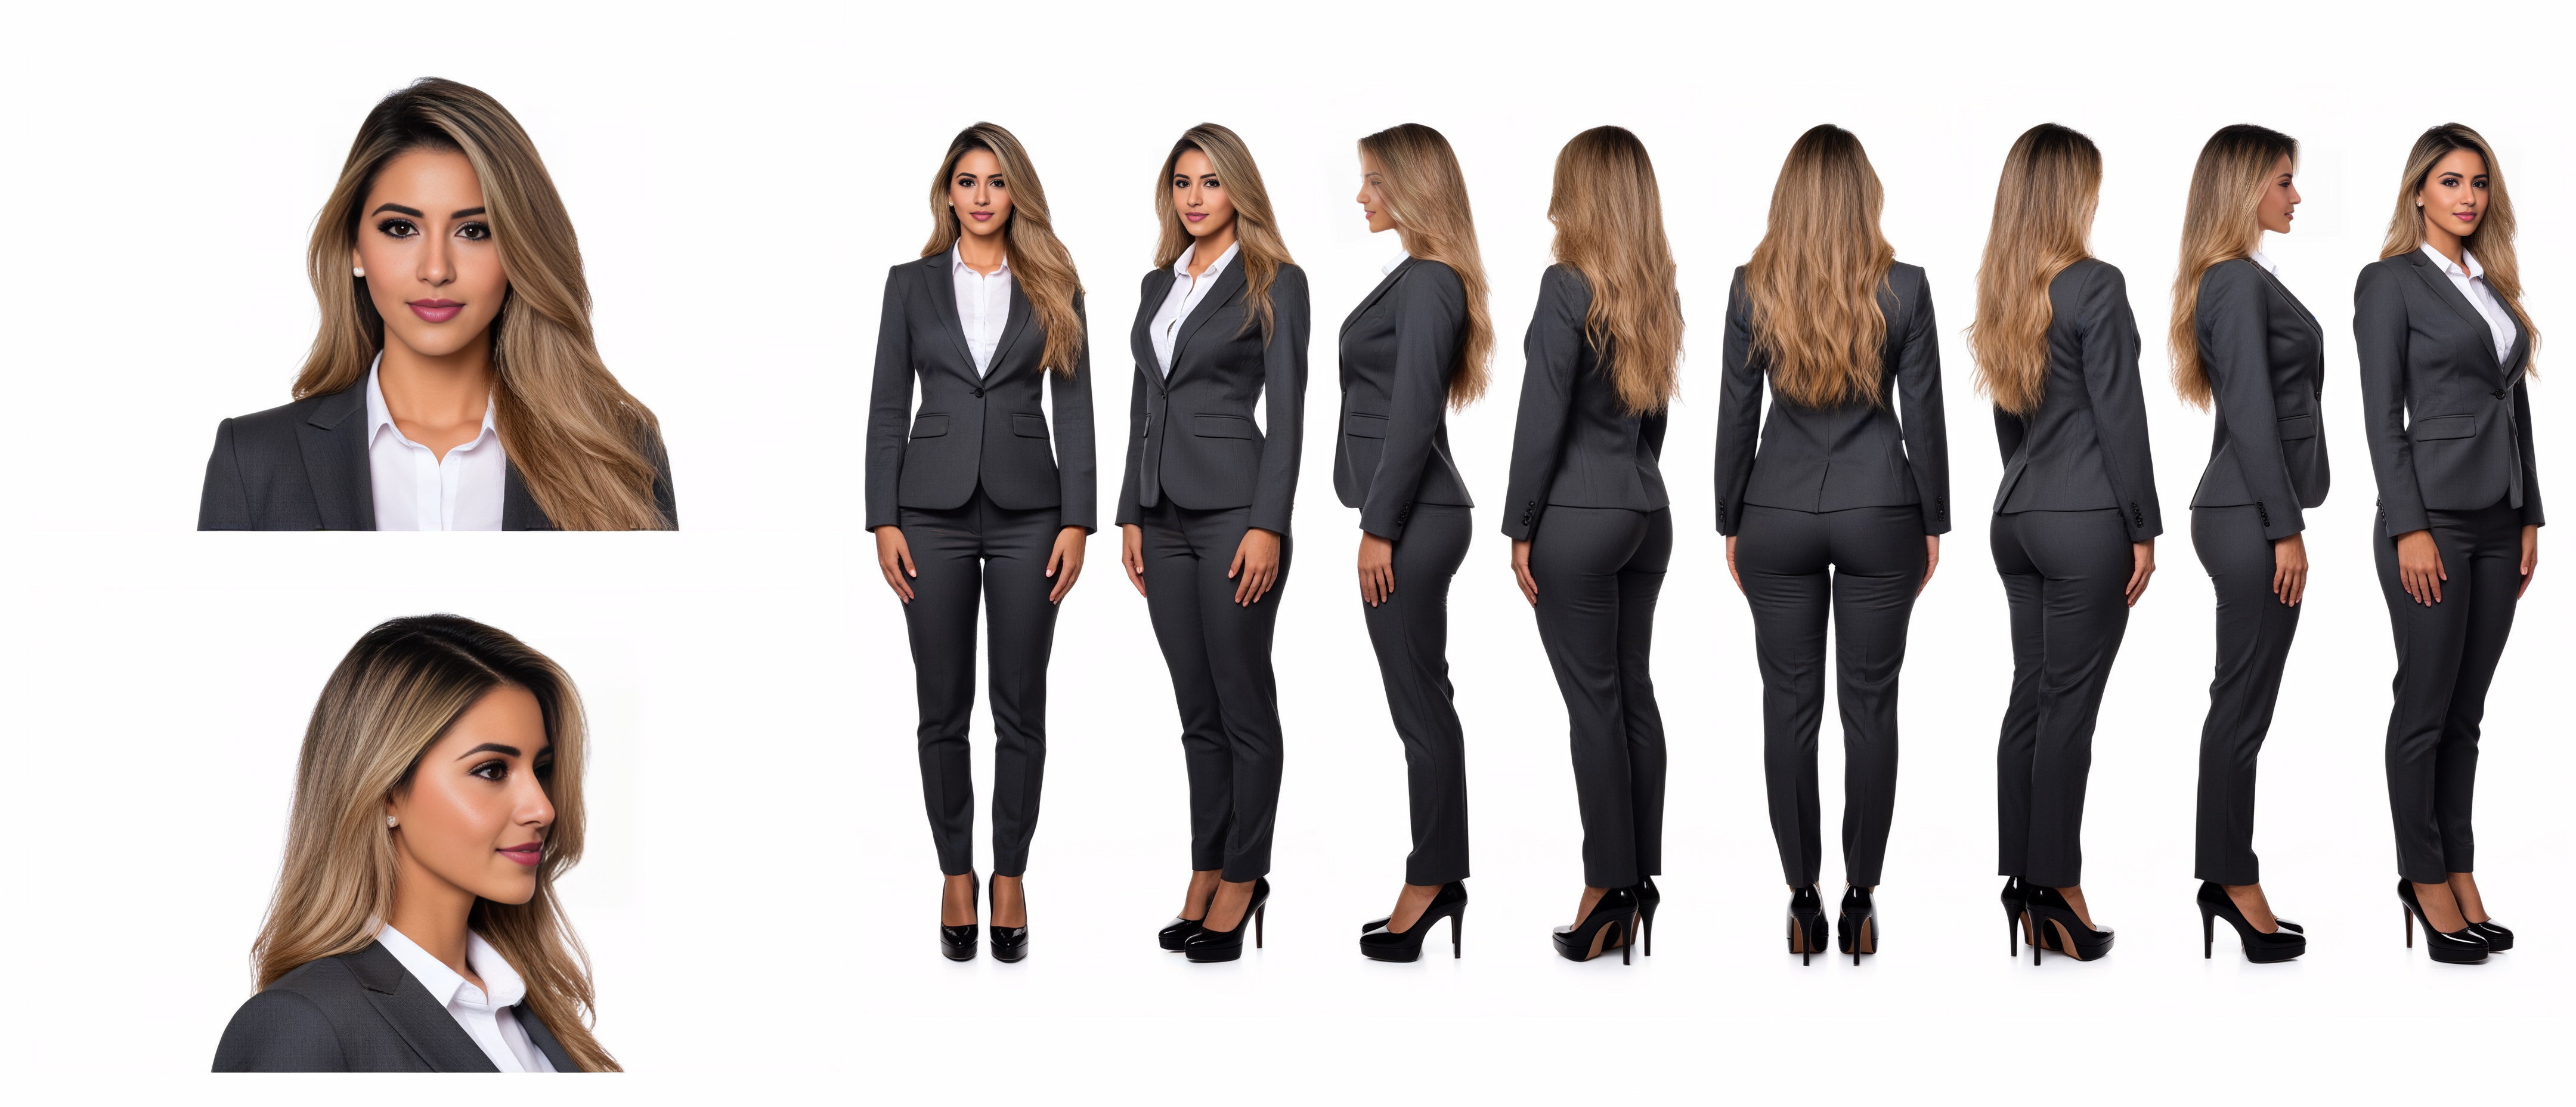

In [16]:
# @title 💥 3. H3 Character Sheet Generator {"single-column":true}
import os
import sys
import gc
import time
import random
import inspect
import torch
import numpy as np
from PIL import Image, ImageDraw
from IPython.display import display, Image as IPImage

sys.path.insert(0, '/content/ComfyUI')
from comfy import model_management
from nodes import (
    UNETLoader,
    CLIPLoader,
    VAELoader,
    VAEDecode,
    LoadImage,
    LoraLoaderModelOnly,
    ConditioningZeroOut,
    KSampler
)
import comfy_extras.nodes_minimax_h3 as h3_nodes
from comfy_extras.nodes_minimax_h3 import MiniMaxH3ImageConditioning

# Properly import PH3ImageConditioning and MiniMaxH3SigmaShift from nodes_minimax_h3
PH3ImageConditioning = getattr(h3_nodes, "PH3ImageConditioning", None)
MiniMaxH3SigmaShift = getattr(h3_nodes, "MiniMaxH3SigmaShift", None)

# @markdown ---
# @markdown ### **1. Media Bank Reference Selection (1 to 3 Images)**
# @markdown Enter the image index numbers `[1]`, `[2]`, etc., from **Cell 2 (Media Bank)**. Set `ref_image_2_index` or `ref_image_3_index` to `0` to disable them:
ref_image_1_index = 1 # @param {type:"integer"}
ref_image_1_role = "Primary Character Identity & Full Appearance" # @param ["Primary Character Identity & Full Appearance", "Face & Hairstyle Reference", "Main Outfit Reference"]

ref_image_2_index = 0 # @param {type:"integer"}
ref_image_2_role = "Outfit / Garment Reference" # @param ["Additional Angle of Same Character", "Face & Hairstyle Close-up", "Outfit / Garment Reference", "Footwear / Shoes Reference", "Accessory / Prop / Weapon Reference"]

ref_image_3_index = 0 # @param {type:"integer"}
ref_image_3_role = "Accessory / Prop / Weapon Reference" # @param ["Additional Angle of Same Character", "Face & Hairstyle Close-up", "Outfit / Garment Reference", "Footwear / Shoes Reference", "Accessory / Prop / Weapon Reference"]

# @markdown ---
# @markdown ### **2. Quick Preset or Custom View Checkboxes**
# @markdown Choose `"Custom (Use Checkboxes Below)"` to mix and match any combination of the 8 head views, 8 full-body views, clothing, hands, and feet:
sheet_preset = "Custom (Use Checkboxes Below)" # @param ["Custom (Use Checkboxes Below)", "Standard 5 Views (2 Head + 3 Body)", "3 Head Views (Front, Side, Back) + 3 Body Views (Front, Side, Back)", "6 Head Views + 3 Body Views (Front, Side, Back)", "6 Head Views + 6 Body Views", "8 Head Views (Full 360°) + 8 Body Views (Full 360°)", "8 Head Views (Full 360°) + 3 Body Views (Front, Side, Back)", "MOSS 7 Views (2 Head + 3 Body + Hands & Feet)", "All 13 Views (6 Head + 3 Body + 2 Outfit + Hands & Feet)"]

apply_face_restoration = True # @param {type:"boolean"}
use_face_setting_2 = True # @param {type:"boolean"}
only_show_face_restored_sheet = True # @param {type:"boolean"}

# @markdown #### **Head Portrait Views (Top Row / Left Column)**
head_front = True # @param {type:"boolean"}
head_front_left = False # @param {type:"boolean"}
head_left = False # @param {type:"boolean"}
head_left_back = False # @param {type:"boolean"}
head_back = False # @param {type:"boolean"}
head_back_right = False # @param {type:"boolean"}
head_right = False # @param {type:"boolean"}
head_front_right = True # @param {type:"boolean"}

# @markdown #### **Full-Body Turnaround Views (Bottom Row / Center Column)**
body_front = True # @param {type:"boolean"}
body_front_left = True # @param {type:"boolean"}
body_left = True # @param {type:"boolean"}
body_left_back = True # @param {type:"boolean"}
body_back = True # @param {type:"boolean"}
body_back_right = True # @param {type:"boolean"}
body_right = True # @param {type:"boolean"}
body_front_right = True # @param {type:"boolean"}

# @markdown #### **Isolated Detail & Garment Panels**
include_hands = False # @param {type:"boolean"}
include_feet = False # @param {type:"boolean"}
include_clothing_front = False # @param {type:"boolean"}
include_clothing_back = False # @param {type:"boolean"}
include_accessories_panel = False # @param {type:"boolean"}

# @markdown ---
# @markdown ### **3. Layout, Conditioning & Resolution Settings**
# @markdown *Selecting `MiniMax H3 Image Conditioning` or `P-H3 Image Conditioning` automatically loads its matching models AND sets its optimal `steps`, `cfg`, `sampler`, and `scheduler`.*
conditioning_node = "P-H3 Image Conditioning" # @param ["MiniMax H3 Image Conditioning", "P-H3 Image Conditioning"]
layout_arrangement = "Columns (MOSS / H3 Designer: Portraits Left, Bodies Center, Details Right)" # @param ["Stacked Rows (Head Portraits Above Full-Body Views)", "Columns (MOSS / H3 Designer: Portraits Left, Bodies Center, Details Right)", "Uniform Multi-Panel Grid"]
use_layout_guide_image = True # @param {type:"boolean"}
show_panel_grid_lines = False # @param {type:"boolean"}
auto_crop_panels = False # @param {type:"boolean"}
crop_inset_px = 0 # @param {type:"slider", min:0, max:32, step:1}
add_crops_to_media_bank = False # @param {type:"boolean"}

aspect_ratio_preset = "21:9 Ultrawide (4320 x 1856 - ~8.0 MP)" # @param ["Auto-Calculate from Selected Views (8.0 MP High-Res)", "Auto-Calculate from Selected Views (4.0 MP Target)", "Auto-Calculate from Selected Views (2.5 MP Low-VRAM)", "16:9 Widescreen (3840 x 2176 - ~8.3 MP)", "21:9 Ultrawide (4320 x 1856 - ~8.0 MP)", "3:2 Landscape (3456 x 2304 - ~8.0 MP)", "4:3 Standard (3264 x 2464 - ~8.0 MP)", "1:1 Square (2816 x 2816 - ~7.9 MP)", "16:9 Widescreen (2688 x 1536 - ~4.1 MP)", "21:9 Ultrawide Sheet (3168 x 1280 - ~4.0 MP)", "3:2 Landscape Sheet (2496 x 1664 - ~4.1 MP)", "4:3 Standard Sheet (2304 x 1728 - ~4.0 MP)", "1:1 Square Sheet (2048 x 2048 - ~4.2 MP)", "Custom Width & Height Below"]
custom_width = 3872 # @param {type:"integer"}
custom_height = 2176 # @param {type:"integer"}

# @markdown ---
# @markdown ### **4. Character & Part Prompts / Style Modifiers**
art_style = "Match Reference Style" # @param ["Match Reference Style", "Photorealistic Studio Reference Sheet", "Anime / Cel-Shaded Production Sheet", "3D Game Character Turnaround Render", "2D Digital Concept Art Illustration", "Clean Line Art & Flat Colors", "Watercolor / Painterly Concept Sheet"]
background_color = "pure solid white studio background" # @param ["pure solid white studio background", "neutral light gray studio background", "clean off-white concept art background"]
character_description = "" # @param {type:"string"}
head_expression_prompt = "neutral calm expression, exact same facial identity" # @param {type:"string"}
clothing_mode = "Worn from Reference" # @param ["Worn from Reference", "Custom Outfit Prompt Below", "No Clothing / Natural Anatomical Mannequin Surface"]
outfit_part_prompt = "" # @param {type:"string"}
hands_feet_prompt = "" # @param {type:"string"}
custom_prompt_override = "" # @param {type:"string"}

# @markdown ---
# @markdown ### **5. Seed, Automatic Sampler Switching & Optional Manual Overrides**
# @markdown *Leave `override_sampler_settings` unchecked (`False`) to automatically apply the recommended `steps`, `cfg`, `sampler`, and `scheduler` for your chosen `conditioning_node`. Check it (`True`) to force the custom values below.*
seed = 3403116873624684743 # @param {type:"integer"}
randomize_seed = False # @param {type:"boolean"}
override_sampler_settings = False # @param {type:"boolean"}
custom_steps = 6 # @param {type:"slider", min:4, max:30, step:1}
custom_cfg = 1.0 # @param {type:"slider", min:1.0, max:7.0, step:0.5}
custom_sampler_name = "euler" # @param ["euler", "uni_pc", "dpmpp_2m", "heun"]
custom_scheduler = "simple" # @param ["simple", "normal", "beta", "sgm_uniform"]
custom_sigma_shift = 1.0 # @param {type:"slider", min:0.5, max:5.0, step:0.1}

# @markdown #### **Optional LoRA Strengths**
lora_1_strength = 1 # @param {type:"slider", min:-2.0, max:2.0, step:0.05}
lora_2_strength = 1 # @param {type:"slider", min:-2.0, max:2.0, step:0.05}
lora_3_strength = 1 # @param {type:"slider", min:-2.0, max:2.0, step:0.05}
lora_4_strength = 1.0 # @param {type:"slider", min:-2.0, max:2.0, step:0.05}
lora_5_strength = 1.0 # @param {type:"slider", min:-2.0, max:2.0, step:0.05}


# ==============================================================================
# STEP 1: AUTOMATIC MODEL & SAMPLER PARAMETER ROUTING (+ OVERRIDE LOGIC)
# ==============================================================================
if conditioning_node == "P-H3 Image Conditioning":
    active_unet_file = globals().get("ph3_unet_file")
    active_clip_file = globals().get("ph3_clip_file")
    active_vae_file = globals().get("ph3_vae_file")
    if not (active_unet_file and active_clip_file and active_vae_file):
        raise ValueError(
            "❌ P-H3-Image models were not downloaded in Cell 1! "
            "Please set `model_download_selection` in Cell 1 to 'Download P-H3-Image Only' or "
            "'Download Both MiniMax-H3-Image & P-H3-Image' and re-run Cell 1."
        )
    default_steps = 8
    default_cfg = 1.0
    default_sampler = "euler"
    default_scheduler = "simple"
    default_shift = 1.0
else:
    active_unet_file = globals().get("minimax_unet_file") or globals().get("unet_model_file")
    active_clip_file = globals().get("minimax_clip_file") or globals().get("text_encoder_file")
    active_vae_file = globals().get("minimax_vae_file") or globals().get("image_vae_file")
    if not (active_unet_file and active_clip_file and active_vae_file):
        raise ValueError(
            "❌ MiniMax-H3-Image models were not downloaded in Cell 1! "
            "Please set `model_download_selection` in Cell 1 to 'Download MiniMax-H3-Image Only' or "
            "'Download Both MiniMax-H3-Image & P-H3-Image' and re-run Cell 1."
        )
    default_steps = 6
    default_cfg = 1.0
    default_sampler = "euler"
    default_scheduler = "simple"
    default_shift = 1.0

if override_sampler_settings:
    active_steps = int(custom_steps)
    active_cfg = float(custom_cfg)
    active_sampler = custom_sampler_name
    active_scheduler = custom_scheduler
    active_shift = float(custom_sigma_shift)
    sampler_mode_label = "MANUAL OVERRIDE"
else:
    active_steps = default_steps
    active_cfg = default_cfg
    active_sampler = default_sampler
    active_scheduler = default_scheduler
    active_shift = default_shift
    sampler_mode_label = f"AUTO ({conditioning_node} Defaults)"


# ==============================================================================
# STEP 2: RESOLVE MEDIA BANK REFERENCE IMAGES (1 TO 3 IMAGES)
# ==============================================================================
BANK_DIR = '/content/ComfyUI/input'
OUTPUT_DIR = '/content/ComfyUI/output'
os.makedirs(OUTPUT_DIR, exist_ok=True)

all_files = os.listdir(BANK_DIR) if os.path.exists(BANK_DIR) else []
available_images = sorted([
    f for f in all_files
    if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')) and not f.startswith('_h3_layout_guide')
])

if not available_images:
    raise FileNotFoundError("❌ No images found in /content/ComfyUI/input. Please run Cell 2 to upload reference images.")

selected_refs = []
raw_selections = [
    (ref_image_1_index, ref_image_1_role),
    (ref_image_2_index, ref_image_2_role),
    (ref_image_3_index, ref_image_3_role),
]

for idx, role in raw_selections:
    if idx > 0:
        if idx > len(available_images):
            raise ValueError(f"❌ Image index [{idx}] is out of range. There are only {len(available_images)} images in the Media Bank.")
        fname = available_images[idx - 1]
        selected_refs.append((fname, role))

if not selected_refs:
    raise ValueError("❌ Please set at least ref_image_1_index to a valid image number (>= 1).")


# ==============================================================================
# STEP 3: RESOLVE ACTIVE VIEWS FROM PRESET OR CHECKBOXES
# ==============================================================================
HEAD_VIEW_SPECS = [
    ("head_front", "front view head portrait", "front head portrait facing straight ahead"),
    ("head_front_left", "front-left three-quarter view head portrait", "45-degree front-left three-quarter head portrait"),
    ("head_left", "left profile view head portrait", "90-degree strict left side profile head portrait"),
    ("head_left_back", "back-left three-quarter view head portrait", "135-degree back-left rear three-quarter head view showing back-left hair and ear"),
    ("head_back", "back view head portrait", "180-degree direct rear head portrait showing back of head and hairstyle"),
    ("head_back_right", "back-right three-quarter view head portrait", "135-degree back-right rear three-quarter head view showing back-right hair and ear"),
    ("head_right", "right profile view head portrait", "90-degree strict right side profile head portrait"),
    ("head_front_right", "front-right three-quarter view head portrait", "45-degree front-right three-quarter head portrait"),
]

BODY_VIEW_SPECS = [
    ("body_front", "full-body front view", "standing full-body front view from head to toe facing forward"),
    ("body_front_left", "full-body front-left three-quarter view", "standing full-body 45-degree front-left three-quarter view from head to toe"),
    ("body_left", "full-body left side view", "standing full-body 90-degree left profile view from head to toe"),
    ("body_left_back", "full-body back-left three-quarter view", "standing full-body 135-degree back-left rear three-quarter view from head to toe"),
    ("body_back", "full-body back view", "standing full-body 180-degree direct rear view from head to toe facing away"),
    ("body_back_right", "full-body back-right three-quarter view", "standing full-body 135-degree back-right rear three-quarter view from head to toe"),
    ("body_right", "full-body right side view", "standing full-body 90-degree right profile view from head to toe"),
    ("body_front_right", "full-body front-right three-quarter view", "standing full-body 45-degree front-right three-quarter view from head to toe"),
]

DETAIL_VIEW_SPECS = [
    ("clothing_front", "isolated front outfit panel", "isolated flat-outfit front view of the garments only, no human body, no head, no limbs"),
    ("clothing_back", "isolated back outfit panel", "isolated flat-outfit back view of the garments only, no human body, no head, no limbs"),
    ("hands", "paired hands close-up panel", "detailed close-up reference panel of left and right hands showing dorsal back-of-hand and open palm views"),
    ("feet", "paired feet and footwear close-up panel", "detailed close-up reference panel of feet and footwear from front, side, and sole angles"),
    ("accessories", "isolated accessories and props callout panel", "detailed close-up callout panel of signature accessories, gear, and props"),
]

active_flags = {
    "head_front": head_front,
    "head_front_left": head_front_left,
    "head_left": head_left,
    "head_left_back": head_left_back,
    "head_back": head_back,
    "head_back_right": head_back_right,
    "head_right": head_right,
    "head_front_right": head_front_right,
    "body_front": body_front,
    "body_front_left": body_front_left,
    "body_left": body_left,
    "body_left_back": body_left_back,
    "body_back": body_back,
    "body_back_right": body_back_right,
    "body_right": body_right,
    "body_front_right": body_front_right,
    "hands": include_hands,
    "feet": include_feet,
    "clothing_front": include_clothing_front,
    "clothing_back": include_clothing_back,
    "accessories": include_accessories_panel,
}

if sheet_preset != "Custom (Use Checkboxes Below)":
    for k in active_flags:
        active_flags[k] = False
    if sheet_preset == "Standard 5 Views (2 Head + 3 Body)":
        for k in ["head_front", "head_left", "body_front", "body_left", "body_back"]:
            active_flags[k] = True
    elif sheet_preset == "3 Head Views (Front, Side, Back) + 3 Body Views (Front, Side, Back)":
        for k in ["head_front", "head_left", "head_back", "body_front", "body_left", "body_back"]:
            active_flags[k] = True
    elif sheet_preset == "6 Head Views + 3 Body Views (Front, Side, Back)":
        for k in ["head_front", "head_front_left", "head_left", "head_back", "head_right", "head_front_right", "body_front", "body_left", "body_back"]:
            active_flags[k] = True
    elif sheet_preset == "6 Head Views + 6 Body Views":
        for k in ["head_front", "head_front_left", "head_left", "head_back", "head_right", "head_front_right",
                  "body_front", "body_front_left", "body_left", "body_back", "body_right", "body_front_right"]:
            active_flags[k] = True
    elif sheet_preset == "8 Head Views (Full 360°) + 8 Body Views (Full 360°)":
        for k, _, _ in HEAD_VIEW_SPECS + BODY_VIEW_SPECS:
            active_flags[k] = True
    elif sheet_preset == "8 Head Views (Full 360°) + 3 Body Views (Front, Side, Back)":
        for k, _, _ in HEAD_VIEW_SPECS:
            active_flags[k] = True
        for k in ["body_front", "body_left", "body_back"]:
            active_flags[k] = True
    elif sheet_preset == "MOSS 7 Views (2 Head + 3 Body + Hands & Feet)":
        for k in ["head_front", "head_left", "body_front", "body_left", "body_back", "hands", "feet"]:
            active_flags[k] = True
    elif sheet_preset == "All 13 Views (6 Head + 3 Body + 2 Outfit + Hands & Feet)":
        for k in ["head_front", "head_front_left", "head_left", "head_back", "head_right", "head_front_right",
                  "body_front", "body_left", "body_back", "clothing_front", "clothing_back", "hands", "feet"]:
            active_flags[k] = True

selected_heads = [(k, short, desc) for k, short, desc in HEAD_VIEW_SPECS if active_flags[k]]
selected_bodies = [(k, short, desc) for k, short, desc in BODY_VIEW_SPECS if active_flags[k]]
selected_details = [(k, short, desc) for k, short, desc in DETAIL_VIEW_SPECS if active_flags[k]]

total_views = len(selected_heads) + len(selected_bodies) + len(selected_details)
if total_views == 0:
    raise ValueError("❌ Please select at least one head, full-body, or detail view checkbox.")


# ==============================================================================
# STEP 4: CALCULATE 32-PIXEL ALIGNED CANVAS DIMENSIONS & OPTIONAL LAYOUT GUIDE
# ==============================================================================
def snap32(val):
    return max(512, int(round(val / 32.0) * 32))

def compute_canvas_dimensions(n_heads, n_bodies, n_details, arrangement, preset_str, c_w, c_h):
    # 8.0 MP Hardcoded Presets
    if preset_str == "16:9 Widescreen (3840 x 2176 - ~8.3 MP)": return 3840, 2176
    elif preset_str == "21:9 Ultrawide (4320 x 1856 - ~8.0 MP)": return 4320, 1856
    elif preset_str == "3:2 Landscape (3456 x 2304 - ~8.0 MP)": return 3456, 2304
    elif preset_str == "4:3 Standard (3264 x 2464 - ~8.0 MP)": return 3264, 2464
    elif preset_str == "1:1 Square (2816 x 2816 - ~7.9 MP)": return 2816, 2816
    # 4.0 MP Hardcoded Presets
    elif preset_str == "16:9 Widescreen (2688 x 1536 - ~4.1 MP)": return 2688, 1536
    elif preset_str == "21:9 Ultrawide Sheet (3168 x 1280 - ~4.0 MP)": return 3168, 1280
    elif preset_str == "3:2 Landscape Sheet (2496 x 1664 - ~4.1 MP)": return 2496, 1664
    elif preset_str == "4:3 Standard Sheet (2304 x 1728 - ~4.0 MP)": return 2304, 1728
    elif preset_str == "1:1 Square Sheet (2048 x 2048 - ~4.2 MP)": return 2048, 2048
    elif preset_str == "Custom Width & Height Below": return snap32(c_w), snap32(c_h)

    # Dynamic Auto-Calculate Target MP
    if "8.0 MP" in preset_str:
        target_mp = 8.0e6
    elif "2.5 MP" in preset_str:
        target_mp = 2.5e6
    else:
        target_mp = 4.0e6

    if "Stacked Rows" in arrangement:
        top_cols = max(1, n_heads) if n_heads > 0 else 0
        bot_cols = max(1, n_bodies + n_details) if (n_bodies + n_details) > 0 else 0
        if top_cols > 0 and bot_cols > 0:
            effective_cols = max(top_cols * 0.75, bot_cols * 0.95, 2.5)
            ratio = min(2.6, max(1.25, effective_cols / 1.85))
        elif top_cols > 0:
            ratio = min(2.6, max(1.0, top_cols * 0.85))
        else:
            ratio = min(2.5, max(0.85, bot_cols * 0.55))
    elif "Columns" in arrangement:
        head_cols = 2 if n_heads > 3 else (1 if n_heads > 0 else 0)
        body_cols = n_bodies
        detail_cols = 2 if n_details > 2 else (1 if n_details > 0 else 0)
        total_unit_width = head_cols * 0.7 + body_cols * 0.95 + detail_cols * 0.75
        ratio = min(2.65, max(1.3, total_unit_width / 1.45))
    else:
        cols = int(np.ceil(np.sqrt(total_views * 1.5)))
        rows = int(np.ceil(total_views / cols))
        ratio = min(2.4, max(1.0, (cols / max(1, rows)) * 0.9))

    h = np.sqrt(target_mp / ratio)
    w = h * ratio
    return snap32(w), snap32(h)

canvas_w, canvas_h = compute_canvas_dimensions(
    len(selected_heads), len(selected_bodies), len(selected_details),
    layout_arrangement, aspect_ratio_preset, custom_width, custom_height
)

def compute_panel_boxes(w, h, heads, bodies, details, arrangement):
    """Returns a list of (key_name, kind, (x0, y0, x1, y1)) for every active view."""
    pad = max(16, int(min(w, h) * 0.02))
    boxes = []

    if "Stacked Rows" in arrangement:
        has_top = len(heads) > 0
        bottom_items = [("body", b[0]) for b in bodies] + [("detail", d[0]) for d in details]
        has_bot = len(bottom_items) > 0

        if has_top and has_bot:
            split_y = int(h * 0.34)
            col_w = (w - pad * (len(heads) + 1)) / len(heads)
            for i, (key, _, _) in enumerate(heads):
                x0 = pad + i * (col_w + pad)
                boxes.append((key, "head", (int(x0), int(pad), int(x0 + col_w), int(split_y - pad // 2))))

            col_w_b = (w - pad * (len(bottom_items) + 1)) / len(bottom_items)
            for i, (knd, key) in enumerate(bottom_items):
                x0 = pad + i * (col_w_b + pad)
                boxes.append((key, knd, (int(x0), int(split_y + pad // 2), int(x0 + col_w_b), int(h - pad))))
        elif has_top:
            col_w = (w - pad * (len(heads) + 1)) / len(heads)
            for i, (key, _, _) in enumerate(heads):
                x0 = pad + i * (col_w + pad)
                boxes.append((key, "head", (int(x0), int(pad), int(x0 + col_w), int(h - pad))))
        else:
            col_w_b = (w - pad * (len(bottom_items) + 1)) / len(bottom_items)
            for i, (knd, key) in enumerate(bottom_items):
                x0 = pad + i * (col_w_b + pad)
                boxes.append((key, knd, (int(x0), int(pad), int(x0 + col_w_b), int(h - pad))))

    elif "Columns" in arrangement:
        zones = []
        if heads: zones.append(("head", [x[0] for x in heads], 0.26 if len(heads) <= 3 else 0.34))
        if bodies: zones.append(("body", [x[0] for x in bodies], 0.50))
        if details: zones.append(("detail", [x[0] for x in details], 0.24))
        total_weight = sum(z[2] for z in zones)
        cur_x = pad
        avail_w = w - pad * (len(zones) + 1)

        for knd, keys, weight in zones:
            zw = avail_w * (weight / total_weight)
            if knd == "body":
                cw = (zw - pad * (len(keys) - 1)) / len(keys)
                for i, key in enumerate(keys):
                    bx0 = cur_x + i * (cw + pad)
                    boxes.append((key, "body", (int(bx0), int(pad), int(bx0 + cw), int(h - pad))))
            else:
                nc = 2 if len(keys) > 3 else 1
                nr = int(np.ceil(len(keys) / nc))
                cw = (zw - pad * (nc - 1)) / nc
                rh = (h - pad * 2 - pad * (nr - 1)) / nr
                for idx, key in enumerate(keys):
                    r, c = idx // nc, idx % nc
                    bx0 = cur_x + c * (cw + pad)
                    by0 = pad + r * (rh + pad)
                    boxes.append((key, knd, (int(bx0), int(by0), int(bx0 + cw), int(by0 + rh))))
            cur_x += zw + pad
    else:
        all_items = [("head", x[0]) for x in heads] + [("body", x[0]) for x in bodies] + [("detail", x[0]) for x in details]
        cols = int(np.ceil(np.sqrt(len(all_items) * 1.5)))
        rows = int(np.ceil(len(all_items) / cols))
        cw = (w - pad * (cols + 1)) / cols
        rh = (h - pad * (rows + 1)) / rows
        for idx, (knd, key) in enumerate(all_items):
            r, c = idx // cols, idx % cols
            bx0 = pad + c * (cw + pad)
            by0 = pad + r * (rh + pad)
            boxes.append((key, knd, (int(bx0), int(by0), int(bx0 + cw), int(by0 + rh))))

    return boxes


def generate_layout_guide_image(w, h, heads, bodies, details, arrangement, save_path, show_borders=True):
    """Draws the spatial layout guide using compute_panel_boxes()."""
    img = Image.new("RGB", (w, h), (255, 255, 255))
    draw = ImageDraw.Draw(img)
    pad = max(16, int(min(w, h) * 0.02))
    border_w = max(3, int(min(w, h) * 0.003))

    panel_boxes = compute_panel_boxes(w, h, heads, bodies, details, arrangement)

    for _, kind, (x0, y0, x1, y1) in panel_boxes:
        pw, ph = x1 - x0, y1 - y0
        cx, cy = (x0 + x1) // 2, (y0 + y1) // 2

        if show_borders:
            draw.rectangle([x0, y0, x1, y1], outline=(40, 40, 40), width=border_w)
            marker_outline = (200, 205, 215)
            marker_fill = None
        else:
            marker_outline = None
            marker_fill = (228, 232, 238)

        if kind == "head":
            r = int(min(pw, ph) * 0.28)
            draw.ellipse([cx - r, cy - int(r * 1.15), cx + r, cy + int(r * 0.95)], fill=marker_fill, outline=marker_outline, width=border_w)
            draw.rounded_rectangle(
                [cx - int(r * 0.85), cy + int(r * 0.95), cx + int(r * 0.85), y1 - pad // 2],
                radius=max(8, r // 3), fill=marker_fill, outline=marker_outline, width=border_w
            )
        elif kind == "body":
            hr = int(min(pw * 0.22, ph * 0.075))
            hy = y0 + int(ph * 0.12)
            draw.ellipse([cx - hr, hy - hr, cx + hr, hy + hr], fill=marker_fill, outline=marker_outline, width=border_w)
            ty0, ty1 = hy + hr + 4, y0 + int(ph * 0.50)
            tw = int(min(pw * 0.30, ph * 0.14))
            draw.rounded_rectangle([cx - tw, ty0, cx + tw, ty1], radius=max(8, tw // 3), fill=marker_fill, outline=marker_outline, width=border_w)
            ly1 = y0 + int(ph * 0.92)
            leg_w = max(border_w * 3, tw // 2) if not show_borders else border_w
            draw.line([cx - tw // 2, ty1, cx - tw // 2, ly1], fill=(228, 232, 238) if not show_borders else (210, 215, 225), width=leg_w)
            draw.line([cx + tw // 2, ty1, cx + tw // 2, ly1], fill=(228, 232, 238) if not show_borders else (210, 215, 225), width=leg_w)
        else:
            ir = int(min(pw, ph) * 0.28)
            draw.rounded_rectangle([cx - ir, cy - ir, cx + ir, cy + ir], radius=max(8, ir // 4), fill=marker_fill, outline=marker_outline, width=border_w)

    img.save(save_path)
    return save_path


# ==============================================================================
# STEP 5: ASSEMBLE MODEL-ALIGNED H3 / P-H3 PROMPT WITH <Picture N> TAGS
# ==============================================================================
conditioning_image_files = [selected_refs[0][0]]
ref_prompt_clauses = [
    f"<Picture 1> is the primary character reference ({selected_refs[0][1]}); preserve the exact person/character, facial identity, skin tone, hair design, body proportions, color palette, and medium from <Picture 1>."
]

next_pic_idx = 2
layout_guide_filename = "_h3_layout_guide.png"
layout_guide_full_path = os.path.join(BANK_DIR, layout_guide_filename)

if use_layout_guide_image:
    generate_layout_guide_image(
        canvas_w, canvas_h, selected_heads, selected_bodies, selected_details,
        layout_arrangement, layout_guide_full_path,
        show_borders=show_panel_grid_lines
    )
    conditioning_image_files.append(layout_guide_filename)
    layout_tag = f"<Picture {next_pic_idx}>"

    if show_panel_grid_lines:
        ref_prompt_clauses.append(
            f"Strictly follow the panel arrangement and rectangular frame borders shown in the layout guide {layout_tag}, filling each framed panel with the corresponding view of the subject from <Picture 1> while leaving no interior silhouette guide shapes visible."
        )
    else:
        ref_prompt_clauses.append(
            f"Use {layout_tag} strictly as an invisible spatial placement guide for the position and scale of each head and full-body view of the subject from <Picture 1>. Render all views on one continuous, seamless, borderless {background_color} with NO grid lines, NO rectangular boxes, NO panel frames, and NO dividing lines."
        )
    next_pic_idx += 1

for extra_fname, extra_role in selected_refs[1:]:
    conditioning_image_files.append(extra_fname)
    ref_prompt_clauses.append(
        f"Use <Picture {next_pic_idx}> as the {extra_role} for the same subject, maintaining full consistency across all views."
    )
    next_pic_idx += 1

style_map = {
    "Match Reference Style": "Preserve the exact realism, photography/rendering style, lighting quality, and surface texture of <Picture 1>.",
    "Photorealistic Studio Reference Sheet": "Cinematic photorealistic studio photograph, 35mm lens, natural skin texture and fabric detail, no illustration, no cartoon, no 3D animated look.",
    "Anime / Cel-Shaded Production Sheet": "Rendered as a clean anime production turnaround character reference sheet with crisp linework and flat cel-shading.",
    "3D Game Character Turnaround Render": "Rendered as a high-resolution 3D game character modeling turnaround sheet with neutral studio lighting and accurate PBR materials.",
    "2D Digital Concept Art Illustration": "Rendered as a polished 2D digital concept art character design sheet with clean edges and clear material definition.",
    "Clean Line Art & Flat Colors": "Clean orthographic character turnaround sheet with precise line art and unshaded flat base colors.",
    "Watercolor / Painterly Concept Sheet": "Detailed painterly watercolor character concept sheet with clean white margins."
}

if clothing_mode == "No Clothing / Natural Anatomical Mannequin Surface":
    clothing_clause = "Depict the subject in a neutral anatomical mannequin surface without outer garments so underlying body proportions are clearly visible."
elif clothing_mode == "Custom Outfit Prompt Below" and outfit_part_prompt.strip():
    clothing_clause = f"Dress the subject consistently in the following outfit across all views: {outfit_part_prompt.strip()}."
elif outfit_part_prompt.strip():
    clothing_clause = f"Keep the outfit from <Picture 1> with these specific details: {outfit_part_prompt.strip()}."
else:
    clothing_clause = "Keep the exact outfit, garment silhouette, and colors worn in <Picture 1> consistent in every view."

layout_clauses = []
if "Stacked Rows" in layout_arrangement:
    if selected_heads and (selected_bodies or selected_details):
        head_list_str = "; ".join([f"({i+1}) {desc}" for i, (_, _, desc) in enumerate(selected_heads)])
        layout_clauses.append(
            f"The reference sheet is organized into two horizontal tiers. "
            f"TOP ROW ({len(selected_heads)} head-and-shoulders close-up portrait panels arranged left to right): {head_list_str}. "
            f"All head portraits show the exact same subject from <Picture 1> with uniform head scale, aligned eye level, and {head_expression_prompt.strip()}."
        )
        bot_descriptions = [desc for _, _, desc in selected_bodies] + [desc for _, _, desc in selected_details]
        bot_list_str = "; ".join([f"({i+1}) {d}" for i, d in enumerate(bot_descriptions)])
        layout_clauses.append(
            f"BOTTOM ROW ({len(bot_descriptions)} panels arranged left to right directly below the portraits): {bot_list_str}. "
            f"Every full-body view shows the complete figure of the subject from <Picture 1> from head to toe with aligned scale and neutral standing posture."
        )
    elif selected_heads:
        head_list_str = "; ".join([f"({i+1}) {desc}" for i, (_, _, desc) in enumerate(selected_heads)])
        layout_clauses.append(
            f"Arrange {len(selected_heads)} head-and-shoulders close-up portrait panels of the subject from <Picture 1> horizontally from left to right: {head_list_str}, with aligned eye level and {head_expression_prompt.strip()}."
        )
    else:
        bot_descriptions = [desc for _, _, desc in selected_bodies] + [desc for _, _, desc in selected_details]
        bot_list_str = "; ".join([f"({i+1}) {d}" for i, d in enumerate(bot_descriptions)])
        layout_clauses.append(
            f"Arrange {len(bot_descriptions)} panels of the subject from <Picture 1> horizontally from left to right: {bot_list_str}, showing complete head-to-toe figures with aligned proportions."
        )
elif "Columns" in layout_arrangement:
    if selected_heads:
        head_list_str = "; ".join([desc for _, _, desc in selected_heads])
        layout_clauses.append(f"LEFT SECTION ({len(selected_heads)} stacked/grid head-and-shoulders portrait panels of <Picture 1>): {head_list_str} with {head_expression_prompt.strip()}.")
    if selected_bodies:
        body_list_str = "; ".join([desc for _, _, desc in selected_bodies])
        layout_clauses.append(f"CENTER SECTION ({len(selected_bodies)} full-height standing turnaround panels of <Picture 1> from head to toe): {body_list_str}.")
    if selected_details:
        detail_list_str = "; ".join([desc for _, _, desc in selected_details])
        layout_clauses.append(f"RIGHT SECTION ({len(selected_details)} isolated callout panels): {detail_list_str}.")
else:
    all_descs = [desc for _, _, desc in (selected_heads + selected_bodies + selected_details)]
    panel_str = "; ".join([f"Panel {i+1}: {d}" for i, d in enumerate(all_descs)])
    layout_clauses.append(f"Arrange {len(all_descs)} distinct, non-overlapping orthographic panels of the subject in <Picture 1> in a clean grid: {panel_str}.")

extra_clauses = []
if character_description.strip():
    extra_clauses.append(f"Subject details: {character_description.strip()}.")
if hands_feet_prompt.strip() and (active_flags["hands"] or active_flags["feet"]):
    extra_clauses.append(f"Hands and footwear details: {hands_feet_prompt.strip()}.")



border_ending = (
    "Clean thin panel borders separating each view, consistent anatomical scale, no overlapping limbs, no text labels, no watermarks."
    if (use_layout_guide_image and show_panel_grid_lines)
    else "Seamless borderless layout with generous clean white space between poses, no grid lines, no boxes, no dividing borders, consistent anatomical scale, no overlapping limbs, no text labels, no watermarks."
)

only_heads = bool(selected_heads) and not selected_bodies and not selected_details
only_bodies = bool(selected_bodies) and not selected_heads and not selected_details

sheet_noun = (
    "multi-angle head portrait reference sheet" if only_heads
    else "full-body turnaround reference sheet" if only_bodies
    else "multi-angle turnaround reference sheet"
)

if only_heads and clothing_mode != "No Clothing / Natural Anatomical Mannequin Surface":
    active_clothing_clause = "Keep the exact hairstyle, accessories, and collar/neckline details from <Picture 1> consistent across every portrait."
else:
    active_clothing_clause = clothing_clause

if only_heads:
    ending_guardrails = (
        "Clean thin panel borders separating each portrait, consistent head proportions, aligned eye level, no text labels, no watermarks."
        if (use_layout_guide_image and show_panel_grid_lines)
        else "Seamless borderless layout with generous clean white space between portraits, no grid lines, no boxes, no dividing borders, consistent head proportions, aligned eye level, no text labels, no watermarks."
    )
else:
    ending_guardrails = border_ending

if custom_prompt_override.strip():
    final_prompt = custom_prompt_override.strip()
else:
    final_prompt = (
        f"Edit <Picture 1>. Create a {total_views}-view {sheet_noun} of the exact subject shown in <Picture 1> "
        f"on a {background_color}. "
        + " ".join(ref_prompt_clauses) + " "
        + " ".join(layout_clauses) + " "
        + active_clothing_clause + " "
        + " ".join(extra_clauses) + " "
        + style_map[art_style] + " "
        + ending_guardrails
    )

actual_seed = random.randint(1, 2**63 - 1) if randomize_seed else int(seed)

print("==================================================================")
print(f"💥 H3 CHARACTER SHEET — {total_views} ACTIVE VIEWS")
print("==================================================================")
print(f"🔹 Conditioning Node : {conditioning_node}")
# print(f"🔹 Selected UNET     : {active_unet_file}")
# print(f"🔹 Selected CLIP     : {active_clip_file}")
# print(f"🔹 Selected VAE      : {active_vae_file}")
print(f"🔹 Target Resolution : {canvas_w} x {canvas_h} ({canvas_w * canvas_h / 1e6:.2f} MP)")
# print(f"🔹 Layout Guide Image: {'ENABLED' if use_layout_guide_image else 'DISABLED (Prompt-Driven Layout)'}")
# print(f"🔹 Active References : {conditioning_image_files}")
# print(f"🔹 Head Views ({len(selected_heads)})   : {[s for _, s, _ in selected_heads]}")
# print(f"🔹 Body Views ({len(selected_bodies)})   : {[s for _, s, _ in selected_bodies]}")
# print(f"🔹 Detail Panels ({len(selected_details)}): {[s for _, s, _ in selected_details]}")
# print(f"🔹 Sampler Mode      : {sampler_mode_label}")
print(f"🔹 Seed={actual_seed}")
print("------------------------------------------------------------------")
print(f"📝 Compiled Prompt:\n{final_prompt}")
print("==================================================================\n")

if use_layout_guide_image:
    print("📐 Generated Spatial Layout Guide Preview:")
    display(IPImage(filename=layout_guide_full_path, width=512))

def save_as_image(image, filename_prefix, output_dir="/content/ComfyUI/output"):
    """Save single frame as PNG image and return (output_path, pil_image)."""
    os.makedirs(output_dir, exist_ok=True)
    output_path = f"{output_dir}/{filename_prefix}.png"

    frame = np.clip(image.cpu().numpy() * 255.0, 0, 255).astype(np.uint8)
    pil_img = Image.fromarray(frame)
    pil_img.save(output_path)

    return output_path, pil_img

# ==============================================================================
# STEP 6: HEADLESS COMFYUI NODE EXECUTION PIPELINE
# ==============================================================================
with torch.inference_mode():
    # 1. Load Reference & Layout Images into Tensor List and Autogrow Dict
    image_loader = LoadImage()
    loaded_image_tensors = []
    for fname in conditioning_image_files:
        img_tensor, _ = image_loader.load_image(fname)
        loaded_image_tensors.append(img_tensor)

    # ComfyUI V3 io.Autogrow passes `images` as a dict {"image_1": tensor1, "image_2": tensor2, ...}
    images_autogrow_dict = {f"image_{i+1}": tensor for i, tensor in enumerate(loaded_image_tensors)}
    # print(f"🖼️ Attached {len(images_autogrow_dict)} reference tensor(s) to conditioning input: {list(images_autogrow_dict.keys())}")

    # 2. Load Active VAE & Text Encoder (CLIP) for Chosen Conditioning Suite
    # print(f"⏳ Loading VAE ({active_vae_file}) and Text Encoder ({active_clip_file})...")
    vae = VAELoader().load_vae(active_vae_file)[0]

    if active_clip_file.lower().endswith(".gguf"):
        from custom_nodes.ComfyUI_GGUF.nodes import CLIPLoaderGGUF
        clip = CLIPLoaderGGUF().load_clip(active_clip_file, type="minimax")[0]
    else:
        clip = CLIPLoader().load_clip(active_clip_file, type="minimax")[0]

    # 3. Encode Reference Conditioning & Empty Latent
    print(f"⏳ Encoding references and prompt with {conditioning_node}...")
    if conditioning_node == "P-H3 Image Conditioning":
        if PH3ImageConditioning is None:
            raise RuntimeError(
                "❌ PH3ImageConditioning was not found in comfy_extras.nodes_minimax_h3. "
                "Run `!git -C /content/ComfyUI pull` to update ComfyUI."
            )
        target_cond_cls = PH3ImageConditioning
    else:
        target_cond_cls = MiniMaxH3ImageConditioning

    sig_params = inspect.signature(target_cond_cls.execute).parameters
    if "images" in sig_params:
        # V3 ComfyNode Autogrow signature: execute(cls, clip, prompt, width, height, vae=None, images=None)
        cond_out = target_cond_cls.execute(
            clip=clip,
            prompt=final_prompt,
            width=canvas_w,
            height=canvas_h,
            vae=vae,
            images=images_autogrow_dict
        )
    else:
        # Fallback if an older/custom signature uses image_1, image_2 kwargs directly
        cond_out = target_cond_cls.execute(
            clip=clip,
            vae=vae,
            prompt=final_prompt,
            width=canvas_w,
            height=canvas_h,
            **images_autogrow_dict
        )

    positive, latent = cond_out[0], cond_out[1]
    negative = ConditioningZeroOut().zero_out(positive)[0]

    # Free Text Encoder from VRAM before loading Diffusion Model
    del clip
    model_management.soft_empty_cache()
    gc.collect()

    # 4. Load Active Diffusion Model (UNET / GGUF) & Apply Optional LoRAs
    # print(f"⏳ Loading Diffusion Model ({active_unet_file})...")
    if active_unet_file.lower().endswith(".gguf"):
        from custom_nodes.ComfyUI_GGUF.nodes import UnetLoaderGGUF
        model = UnetLoaderGGUF().load_unet(active_unet_file)[0]
    else:
        model = UNETLoader().load_unet(active_unet_file, "default")[0]

    # Apply Optional LoRAs from Cell 1 if downloaded
    if 'lora_files' in globals():
        lora_strengths = [lora_1_strength, lora_2_strength, lora_3_strength, lora_4_strength, lora_5_strength]
        for l_file, l_str in zip(lora_files, lora_strengths):
            if l_file and l_str != 0.0:
                print(f"🔗 Applying LoRA: {l_file} (strength={l_str})")
                model = LoraLoaderModelOnly().load_lora_model_only(model, l_file, l_str)[0]

    # Apply Sigma Shift (automatically applied for P-H3, or if manually overridden)
    if (conditioning_node == "P-H3 Image Conditioning" or override_sampler_settings) and MiniMaxH3SigmaShift is not None:
        try:
            model = MiniMaxH3SigmaShift.execute(model=model, shift=active_shift, audio_shift=active_shift)[0]
        except Exception:
            pass

    # 5. KSampler Execution using Active (Auto or Overridden) Settings
    # print(f"🚀 Sampling Character Sheet ({canvas_w}x{canvas_h}, {active_steps} steps, sampler={active_sampler}, scheduler={active_scheduler})...")
    print("Generating Character Sheet...")
    sampled_latent = KSampler().sample(
        model=model,
        seed=actual_seed,
        steps=active_steps,
        cfg=active_cfg,
        sampler_name=active_sampler,
        scheduler=active_scheduler,
        positive=positive,
        negative=negative,
        latent_image=latent,
        denoise=1.0
    )[0]

    # Free Diffusion Model before VAE Decode to prevent OOM at 4MP+
    del model, positive, negative
    model_management.soft_empty_cache()
    gc.collect()

    # 6. VAE Decode & Save Output
    # print("⏳ Decoding latent with VAE...")
    decoded_tensor = VAEDecode().decode(vae, sampled_latent)[0]

    del vae, sampled_latent
    model_management.soft_empty_cache()
    gc.collect()

    # Convert tensor [B, H, W, C] or [B, F, H, W, C] to PIL Image (take frame 0)
    img_np = decoded_tensor.cpu().numpy()
    while img_np.ndim > 3:
        img_np = img_np[0]
    img_uint8 = np.clip(img_np * 255.0, 0, 255).astype(np.uint8)
    result_pil = Image.fromarray(img_uint8)

    suite_tag = "PH3" if conditioning_node == "P-H3 Image Conditioning" else "MiniMaxH3"
    timestamp = time.strftime("%Y%m%d_%H%M%S")
    out_filename = os.path.join(OUTPUT_DIR, f"{suite_tag}_Character_Sheet_{total_views}views_{timestamp}.png")
    result_pil.save(out_filename)

    print(f"✅ Character Sheet Saved to: {out_filename}\n")
    if only_show_face_restored_sheet is False:
        display(IPImage(filename=out_filename))


    if auto_crop_panels and (apply_face_restoration is False):
        import math
        import shutil
        import matplotlib.pyplot as plt

        if not use_layout_guide_image:
            print("⚠️ Note: `use_layout_guide_image` was False; cropping uses estimated layout bounds.")

        crops_dir = os.path.join(OUTPUT_DIR, f"{suite_tag}_Panels_{timestamp}")
        os.makedirs(crops_dir, exist_ok=True)

        img_w, img_h = result_pil.size
        panel_boxes = compute_panel_boxes(
            img_w, img_h, selected_heads, selected_bodies, selected_details, layout_arrangement
        )

        saved_crops = []
        inset = int(crop_inset_px)

        for idx, (view_key, _, (x0, y0, x1, y1)) in enumerate(panel_boxes, 1):
            cx0 = max(0, min(img_w - 1, x0 + inset))
            cy0 = max(0, min(img_h - 1, y0 + inset))
            cx1 = max(cx0 + 1, min(img_w, x1 - inset))
            cy1 = max(cy0 + 1, min(img_h, y1 - inset))

            crop_img = result_pil.crop((cx0, cy0, cx1, cy1))
            crop_name = f"{idx:02d}_{view_key}.png"
            crop_path = os.path.join(crops_dir, crop_name)
            crop_img.save(crop_path)
            saved_crops.append((crop_name, crop_img))

            if add_crops_to_media_bank:
                bank_copy_path = os.path.join(BANK_DIR, f"{suite_tag}_{timestamp}_{crop_name}")
                shutil.copy2(crop_path, bank_copy_path)

        print(f"✂️ Saved {len(saved_crops)} cropped panel PNGs to: {crops_dir}")
        if add_crops_to_media_bank:
            print(f"📥 Also copied cropped panels into Media Bank ({BANK_DIR}). Re-run Cell 2 to see their indices.")

        # Display a compact thumbnail grid of the cropped panels
        cols = min(5, len(saved_crops))
        rows = math.ceil(len(saved_crops) / cols)
        fig, axes = plt.subplots(rows, cols, figsize=(3.5 * cols, 4.0 * rows))
        axes = np.atleast_1d(axes).flatten()

        for i, (cname, cimg) in enumerate(saved_crops):
            axes[i].imshow(cimg)
            axes[i].set_title(cname.replace(".png", ""), fontsize=10, fontweight="bold")
            axes[i].axis("off")

        for j in range(len(saved_crops), len(axes)):
            axes[j].axis("off")

        plt.tight_layout()
        plt.show()

    if apply_face_restoration or only_show_face_restored_sheet:

        print("Restoring faces...")

        reactor_instance = reactor()


        input_faces_indexf="0"
        if use_face_setting_2:
            input_faces_indexf=",".join(str(i) for i in range(total_views))

        decoded, _ = reactor_instance.execute(
                      enabled=True,
                      input_image=decoded_tensor,
                      swap_model="inswapper_128.onnx",
                      detect_gender_source="no",
                      detect_gender_input="no",
                      source_faces_index="0",
                      input_faces_index=input_faces_indexf,
                      console_log_level=0,
                      face_restore_model="GFPGANv1.4.pth",
                      face_restore_visibility=1.0,
                      codeformer_weight=0.5,
                      facedetection="retinaface_resnet50",
                      source_image=loaded_image_tensors[0],
                      face_model=None,
                      faces_order=None,
                      face_boost=None
                  )

        output_path = ""

        base_name = "character_sheet"

        base_name += f"_{timestamp}"

        # output_path = save_as_image(decoded[-1], base_name)

        output_path, result_pil = save_as_image(decoded[-1], base_name)
        display(IPImage(filename=output_path))

        if auto_crop_panels:
            import math
            import shutil
            import matplotlib.pyplot as plt

            if not use_layout_guide_image:
                print("⚠️ Note: `use_layout_guide_image` was False; cropping uses estimated layout bounds.")

            crops_dir = os.path.join(OUTPUT_DIR, f"{suite_tag}_Panels_{timestamp}")
            os.makedirs(crops_dir, exist_ok=True)

            img_w, img_h = result_pil.size
            panel_boxes = compute_panel_boxes(
                img_w, img_h, selected_heads, selected_bodies, selected_details, layout_arrangement
            )

            saved_crops = []
            inset = int(crop_inset_px)

            for idx, (view_key, _, (x0, y0, x1, y1)) in enumerate(panel_boxes, 1):
                cx0 = max(0, min(img_w - 1, x0 + inset))
                cy0 = max(0, min(img_h - 1, y0 + inset))
                cx1 = max(cx0 + 1, min(img_w, x1 - inset))
                cy1 = max(cy0 + 1, min(img_h, y1 - inset))

                crop_img = result_pil.crop((cx0, cy0, cx1, cy1))
                crop_name = f"{idx:02d}_{view_key}.png"
                crop_path = os.path.join(crops_dir, crop_name)
                crop_img.save(crop_path)
                saved_crops.append((crop_name, crop_img))

                if add_crops_to_media_bank:
                    bank_copy_path = os.path.join(BANK_DIR, f"{suite_tag}_{timestamp}_{crop_name}")
                    shutil.copy2(crop_path, bank_copy_path)

            print(f"✂️ Saved {len(saved_crops)} cropped panel PNGs to: {crops_dir}")
            if add_crops_to_media_bank:
                print(f"📥 Also copied cropped panels into Media Bank ({BANK_DIR}). Re-run Cell 2 to see their indices.")

            # Display a compact thumbnail grid of the cropped panels
            cols = min(5, len(saved_crops))
            rows = math.ceil(len(saved_crops) / cols)
            fig, axes = plt.subplots(rows, cols, figsize=(3.5 * cols, 4.0 * rows))
            axes = np.atleast_1d(axes).flatten()

            for i, (cname, cimg) in enumerate(saved_crops):
                axes[i].imshow(cimg)
                axes[i].set_title(cname.replace(".png", ""), fontsize=10, fontweight="bold")
                axes[i].axis("off")

            for j in range(len(saved_crops), len(axes)):
                axes[j].axis("off")

            plt.tight_layout()
            plt.show()

        del decoded
        model_management.soft_empty_cache()
        gc.collect()